## 1 · Imports et chargement des données

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

df_raw = pd.read_csv("../data/weatherAUS.csv")
print(f"Loaded {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")

Loaded 145,460 rows x 23 columns


---
## 2. Codage Cyclique des Dates : nettoyage initial et caractéristiques temporelles

### 2.1. Nettoyage initial et codage cyclique des dates

In [2]:
df = df_raw.copy()

# Parse dates
df['Date'] = pd.to_datetime(df['Date'])

# Map binary columns
binary_mapping = {'Yes': True, 'No': False}
df['RainToday']    = df['RainToday'].map(binary_mapping).astype('boolean')
df['RainTomorrow'] = df['RainTomorrow'].map(binary_mapping).astype('boolean')

# Drop rows where target variables are unknown
df = df.dropna(subset=['RainToday', 'RainTomorrow']).copy()

print(f"After target cleaning: {df.shape[0]:,} rows")
df[['Date', 'RainToday', 'RainTomorrow']].head()


After target cleaning: 140,787 rows


,Date,RainToday,RainTomorrow
0,2008-12-01,False,False
1,2008-12-02,False,False
2,2008-12-03,False,False
3,2008-12-04,False,False
4,2008-12-05,False,False


### 2.2 · Codage cyclique de `Date`

In [3]:
# Extract day of the year (1-366)
day_of_year = df['Date'].dt.dayofyear

# Define the period (365.25 for average days in a year)
max_days = 365.25

# Create cyclic features
df['Date_sin'] = np.sin(2 * np.pi * day_of_year / max_days)
df['Date_cos'] = np.cos(2 * np.pi * day_of_year / max_days)

print("Cyclic encoding for 'Date' completed.")
print(df[['Date', 'Date_sin', 'Date_cos']].head(10))


Cyclic encoding for 'Date' completed.
        Date  Date_sin  Date_cos
0 2008-12-01 -0.482206  0.876058
1 2008-12-02 -0.467065  0.884223
2 2008-12-03 -0.451786  0.892126
3 2008-12-04 -0.436373  0.899766
4 2008-12-05 -0.420831  0.907139
5 2008-12-06 -0.405165  0.914244
6 2008-12-07 -0.389378  0.921078
7 2008-12-08 -0.373477  0.927640
8 2008-12-09 -0.357464  0.933927
9 2008-12-10 -0.341347  0.939938


### 2.3 · Valider le codage cyclique

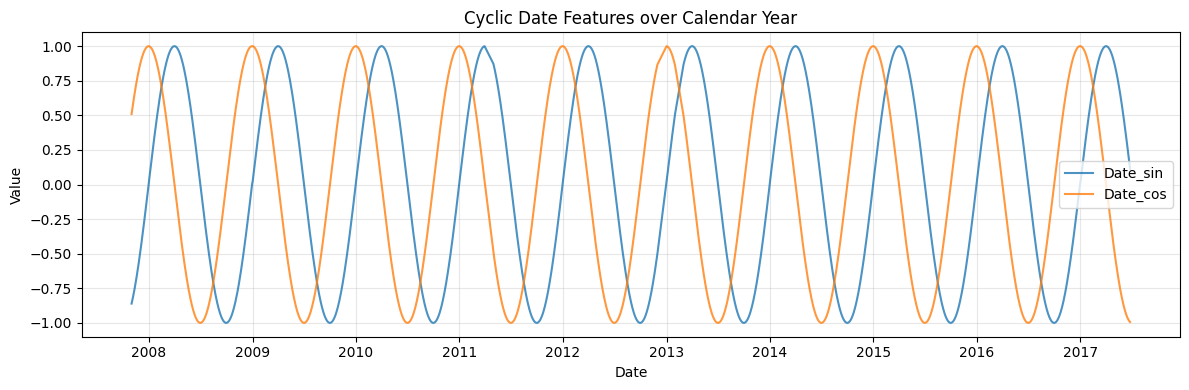

Date_sin range: [-1.0000, 1.0000]
Date_cos range: [-1.0000, 1.0000]


In [4]:
# Quick sanity check: plot Date_sin and Date_cos over the calendar year
sample = df[['Date', 'Date_sin', 'Date_cos']].sort_values('Date').drop_duplicates('Date')

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(sample['Date'], sample['Date_sin'], label='Date_sin', alpha=0.8)
ax.plot(sample['Date'], sample['Date_cos'], label='Date_cos', alpha=0.8)
ax.set_title('Cyclic Date Features over Calendar Year')
ax.set_xlabel('Date')
ax.set_ylabel('Value')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Date_sin range: [{df['Date_sin'].min():.4f}, {df['Date_sin'].max():.4f}]")
print(f"Date_cos range: [{df['Date_cos'].min():.4f}, {df['Date_cos'].max():.4f}]")


`Date_sin` et `Date_cos` capturent le cycle saisonnier sans aucune étiquette de mois catégorique ou étiquette de groupe.

Les deux caractéristiques seront utilisées directement comme prédicteurs dans toutes les étapes d'imputation MICE ultérieures, remplaçant l'ancienne colonne `Month`.

---
## 3. Groupes Climatiques : regroupement multi-caractéristiques

### 3.1 · Regroupement K-Means sur les caractéristiques climatiques (Température + Humidité + Précipitations)

In [5]:
CLIMATE_FEATURES = ['MinTemp','MaxTemp','Temp9am','Temp3pm','Humidity9am','Humidity3pm','Rainfall']

trend_climate = df.groupby('Location')[CLIMATE_FEATURES].mean().reset_index()

pivot_climate = trend_climate.set_index('Location')
pivot_climate = pivot_climate.dropna()

scaler_c = StandardScaler()
X_clim = scaler_c.fit_transform(pivot_climate)

N_CLUSTERS_CLIMATE = 4
km_clim = KMeans(n_clusters=N_CLUSTERS_CLIMATE, random_state=RANDOM_STATE, n_init=10)
pivot_climate['Cluster'] = km_clim.fit_predict(X_clim)

for i in range(N_CLUSTERS_CLIMATE):
    locs = pivot_climate[pivot_climate['Cluster'] == i].index.tolist()
    print(f"Cluster {i}: {', '.join(locs)}")


Cluster 0: Adelaide, AliceSprings, Cobar, Mildura, Moree, PearceRAAF, Perth, PerthAirport, SalmonGums, Uluru, Woomera
Cluster 1: Albury, Ballarat, Bendigo, Canberra, Dartmoor, Hobart, Launceston, Melbourne, MelbourneAirport, MountGambier, MountGinini, Nhil, Nuriootpa, Portland, Sale, Tuggeranong, WaggaWagga, Watsonia
Cluster 2: Albany, BadgerysCreek, Brisbane, CoffsHarbour, GoldCoast, Newcastle, NorahHead, NorfolkIsland, Penrith, Richmond, Sydney, SydneyAirport, Walpole, Williamtown, Witchcliffe, Wollongong
Cluster 3: Cairns, Darwin, Katherine, Townsville


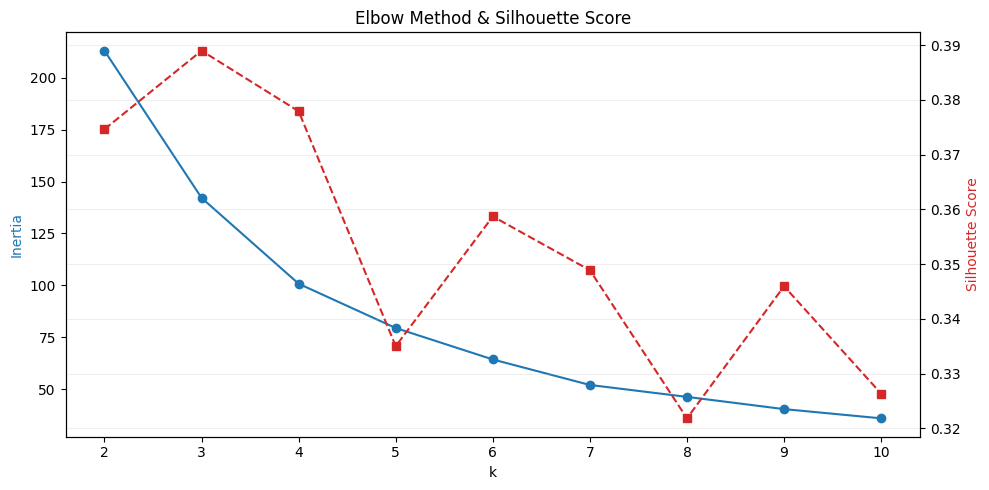

In [6]:
# Elbow + silhouette to validate k=4
from sklearn.metrics import silhouette_score

inertia, sil_scores = [], []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_clim)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(X_clim, labels))

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(K_range, inertia, 'o-', color='tab:blue', label='Inertia')
ax1.set_xlabel('k')
ax1.set_ylabel('Inertia', color='tab:blue')
ax2 = ax1.twinx()
ax2.plot(K_range, sil_scores, 's--', color='tab:red', label='Silhouette')
ax2.set_ylabel('Silhouette Score', color='tab:red')
plt.title('Elbow Method & Silhouette Score')
fig.tight_layout()
plt.grid(True, alpha=0.2)
plt.show()


- La courbe d'inertie diminue rapidement pour les premiers `k`, puis son gain devient beaucoup plus faible à partir de `k=4`. Le « coude » suggère qu'ajouter plus de clusters apporte peu d'amélioration.

- Le score de silhouette mesure la qualité de séparation entre clusters. S'il est maximal ou stable autour de `k=4`, cela indique des groupes bien distincts et cohérents.

- Ensemble, ces deux critères valident le choix de `k=4` pour le regroupement climatique.

- En pratique, cela signifie que la segmentation en 4 groupes (`TS`, `CS`, `TP`, `AI`) est un bon compromis entre explicabilité et structure réelle des données.

### 3.2 · Visualisation PCA des groupes climatiques

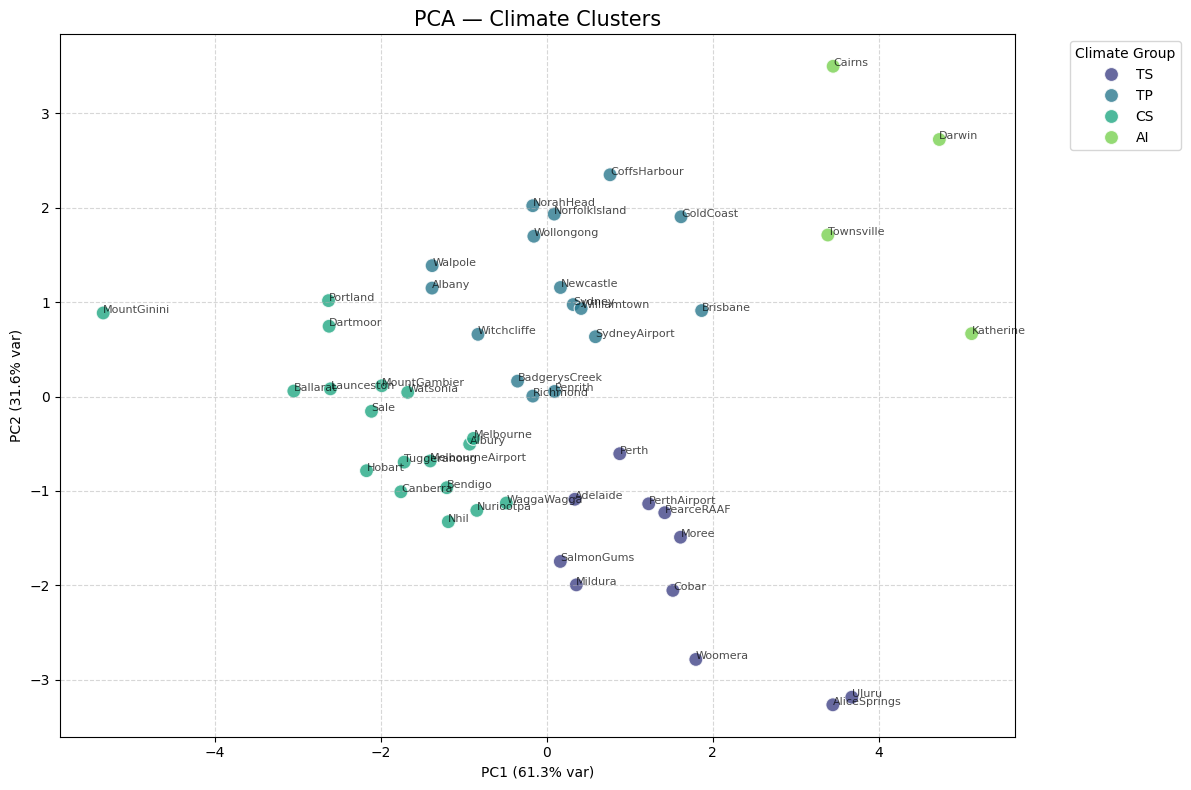

In [7]:
CLIMATE_CLUSTER_MAP = {0: 'TS', 1: 'CS', 2: 'TP', 3: 'AI'}

pca_c = PCA(n_components=2)
X_pca_c = pca_c.fit_transform(X_clim)
pca_df_c = pd.DataFrame(X_pca_c, columns=['PC1','PC2'], index=pivot_climate.index)
pca_df_c['Cluster'] = pivot_climate['Cluster'].map(CLIMATE_CLUSTER_MAP)

plt.figure(figsize=(12, 8))
sns.scatterplot(x='PC1', y='PC2', hue='Cluster', palette='viridis',
                data=pca_df_c, s=100, alpha=0.8)
for i, loc in enumerate(pca_df_c.index):
    plt.annotate(loc, (pca_df_c.PC1.iloc[i], pca_df_c.PC2.iloc[i]),
                 fontsize=8, alpha=0.7)
plt.title('PCA — Climate Clusters', fontsize=15)
plt.xlabel(f'PC1 ({pca_c.explained_variance_ratio_[0]:.1%} var)')
plt.ylabel(f'PC2 ({pca_c.explained_variance_ratio_[1]:.1%} var)')
plt.legend(title='Climate Group', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 3.3 · Assigner `weather_trend_group` au DataFrame principal

In [8]:
location_label_map = (
    pivot_climate['Cluster']
    .map(CLIMATE_CLUSTER_MAP)
    .to_dict()
)
df['weather_trend_group'] = df['Location'].map(location_label_map)

missing_group = df['weather_trend_group'].isna().sum()
print(f"Rows without a climate group: {missing_group}")
print("\nGroup distribution:")
display(df['weather_trend_group'].value_counts(dropna=False).to_frame())

Rows without a climate group: 0

Group distribution:


,count
weather_trend_group,
CS,52171
TP,46792
TS,31096
AI,10728


### 3.4 ·  La variation des feature classées par `weather_trend_group` en fonction du mois

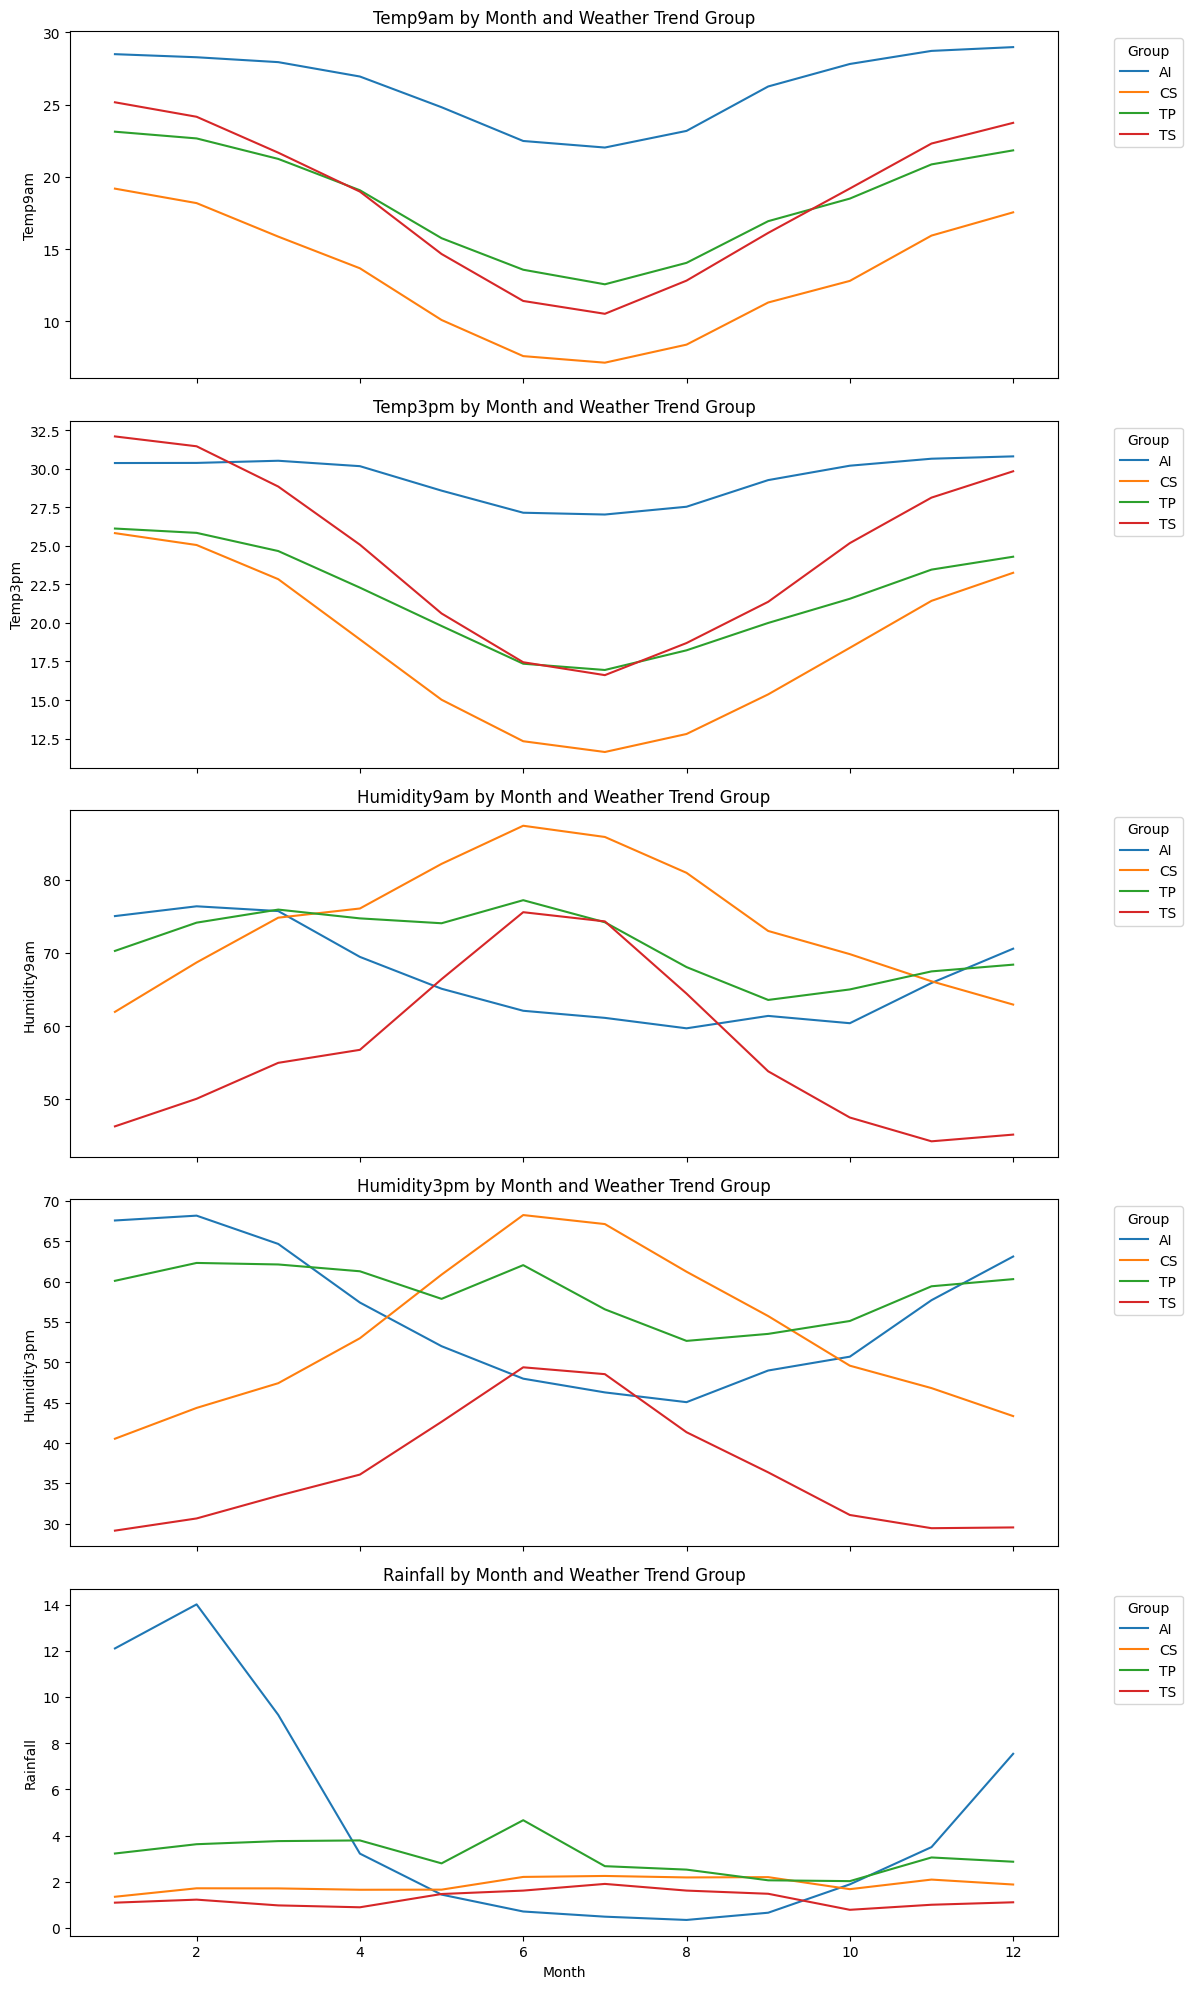

In [9]:
# Select features to visualize
features = ['Temp9am', 'Temp3pm', 'Humidity9am', 'Humidity3pm', 'Rainfall']

# Group by weather_trend_group and Month, compute mean
df['Month'] = df['Date'].dt.month
grouped = df.groupby(['weather_trend_group', 'Month'])[features].mean().reset_index()

# Create subplots for each feature
fig, axes = plt.subplots(len(features), 1, figsize=(12, 20), sharex=True)

for i, feature in enumerate(features):
    sns.lineplot(data=grouped, x='Month', y=feature, hue='weather_trend_group', ax=axes[i])
    axes[i].set_title(f'{feature} by Month and Weather Trend Group')
    axes[i].set_xlabel('Month')
    axes[i].set_ylabel(feature)
    axes[i].legend(title='Group', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

### 3.5 · Analyse des valeurs manquantes par groupe

In [10]:
missing_by_group = df.groupby('weather_trend_group').apply(
    lambda x: x.isnull().mean() * 100
)
print("% missing by climate group:")
display(missing_by_group.T.style.background_gradient(cmap='YlOrRd', axis=1))

% missing by climate group:


weather_trend_group,AI,CS,TP,TS
Date,0.000000,0.000000,0.000000,0.000000
Location,0.000000,0.000000,0.000000,0.000000
MinTemp,0.307606,0.116923,0.730894,0.102907
MaxTemp,0.205071,0.067087,0.482989,0.077180
Rainfall,0.000000,0.000000,0.000000,0.000000
Evaporation,4.912379,42.659715,57.334587,32.425392
Sunshine,22.026473,46.629353,63.047102,34.133007
WindGustDir,1.043997,1.857354,16.342537,1.398894
WindGustSpeed,0.997390,1.822852,16.269875,1.395678
WindDir9am,2.171887,7.471584,9.490939,3.498842


In [11]:
# Assess data loss from dropping key rows
CORE_COLS = ['MinTemp','MaxTemp','Humidity9am','Rainfall']

def calculate_loss(group):
    initial = len(group)
    after   = len(group.dropna(subset=CORE_COLS))
    lost    = initial - after
    return pd.Series({'Initial': initial, 'Remaining': after,
                      'Lost': lost, 'Loss %': lost / initial * 100})

loss_df = df.groupby('weather_trend_group').apply(calculate_loss)
display(loss_df.style.format({'Loss %': '{:.2f}%'}))
print(f"\nOverall loss: {(len(df) - len(df.dropna(subset=CORE_COLS))) / len(df) * 100:.2f}%")

,Initial,Remaining,Lost,Loss %
weather_trend_group,,,,
AI,10728.000000,10632.000000,96.000000,0.89%
CS,52171.000000,51421.000000,750.000000,1.44%
TP,46792.000000,45869.000000,923.000000,1.97%
TS,31096.000000,30898.000000,198.000000,0.64%



Overall loss: 1.40%


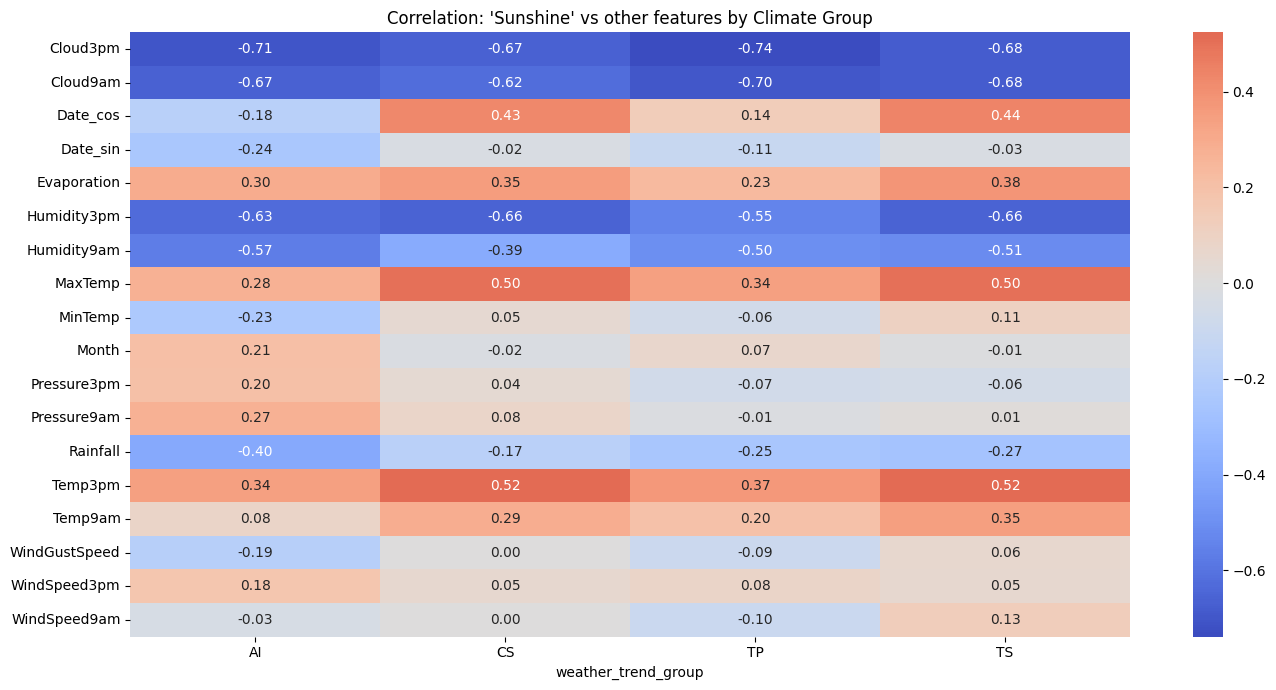

In [12]:
# Sunshine correlation per group
numeric_cols = df.select_dtypes(include='number').columns.tolist()

def sunshine_corr(g):
    cm = g[numeric_cols].corr()
    return cm['Sunshine'].sort_values(ascending=False) if 'Sunshine' in cm else None

sun_corr = df.groupby('weather_trend_group').apply(sunshine_corr, include_groups=False)

plt.figure(figsize=(14, 7))
sns.heatmap(
    sun_corr.unstack().drop(columns='Sunshine', errors='ignore').T,
    annot=True, fmt='.2f', cmap='coolwarm', center=0
)
plt.title("Correlation: 'Sunshine' vs other features by Climate Group")
plt.tight_layout()
plt.show()

### 3.6 · Supprimer les lignes manquant les caractéristiques principales

In [13]:
REQUIRED_COLS = ['MinTemp','MaxTemp','Rainfall','Humidity9am','Temp9am','RainToday']
df.dropna(subset=REQUIRED_COLS, inplace=True)
print(f"Shape after dropping rows missing core features: {df.shape}")

Shape after dropping rows missing core features: (138820, 27)


---
## 4. Export des données

In [14]:
OUTPUT_PATH = "../data/weatherAUS_trend_grouped.csv"
df.to_csv(OUTPUT_PATH, index=False)
print(f"Saved → {OUTPUT_PATH}  ({df.shape[0]:,} rows x {df.shape[1]} cols)")

Saved → ../data/weatherAUS_trend_grouped.csv  (138,820 rows x 27 cols)
